# Modelado · RNN, LSTM y GRU

**Caso de uso III · Aprendizaje automático**

Este notebook recoge el entrenamiento y la comparación de las tres redes recurrentes. Irá creciendo por fases (ver D16 en `docs/diario_de_ruta.md`):

| Sección | Contenido | Estado |
|---|---|---|
| 1 | Prueba inicial con la configuración base | ✅ |
| 2 | Fase A: estudio de ventana × recorte × nivel | en curso (ventanas 10-60 hechas) |
| 3 | Fase B: búsqueda de la mejor configuración de cada red (Optuna) | pendiente |
| 4 | Examen final en test y tabla comparativa | pendiente |

El código está en `src/oil_price/`: `modelos.py` (las tres redes comparten estructura y solo cambia la celda; modelo lineal de referencia), `entrenamiento.py` (igual para las tres) y `evaluacion.py` (métricas y comparación con el ingenuo).

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oil_price import config, datos, entrenamiento as ent, evaluacion as ev, preprocesado as pp
from oil_price.graficos import C, EJE, FONDO, TINTA, TINTA_2, aplicar_estilo
from oil_price.modelos import ModeloLineal

aplicar_estilo()
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.3f}".format)
COLOR_RED = {"RNN": C["azul"], "LSTM": C["naranja"], "GRU": C["aqua"]}
print("Dispositivo de cálculo:", ent.dispositivo_disponible())

Dispositivo de cálculo: cpu


## 1. Prueba inicial con la configuración base

**Objetivo:** comprobar que todo el circuito funciona con datos reales y ver cómo se comportan las redes **sin ajustar nada**. No es un resultado del estudio: es un solo pliegue y una sola configuración.

- **Pliegue 1:** entrenamiento hasta el 31/12/2017 y validación en 2018.
- **Datos:** ventana de 60 días, recorte 1-99 % e indicador de nivel incluido.
- **Estructura base, igual para las tres:** 64 neuronas, 1 capa, dropout 0,2, velocidad de aprendizaje 0,001, lotes de 64.
- **Referencias:** modelo ingenuo y modelo lineal (Ridge).

In [2]:
base = pp.preparar_base(datos.cargar_datos_limpios())
pliegue = pp.pliegues_walk_forward()[0]
train, val, _ = pp.construir_particion(base, 60, (1.0, 99.0), **pliegue)
print(f"Train: {len(train):,} fichas ({train.fechas[0]:%d/%m/%Y} → {train.fechas[-1]:%d/%m/%Y})")
print(f"Validación: {len(val):,} fichas ({val.fechas[0]:%d/%m/%Y} → {val.fechas[-1]:%d/%m/%Y})")
print("Configuración base:", config.HIPERPARAMETROS_BASE)

Train: 3,814 fichas (03/04/2002 → 29/12/2017)
Validación: 252 fichas (02/01/2018 → 28/12/2018)
Configuración base: {'unidades': 64, 'capas': 1, 'dropout': 0.2, 'lr': 0.001, 'l2': 0.0, 'lote': 64}


In [3]:
resultados = {celda: ent.entrenar_red(celda, train) for celda in config.CELDAS}
lineal = ModeloLineal(alfa=1e4).ajustar(train)

predicciones = {celda: ent.predecir(r, val.X) for celda, r in resultados.items()}
predicciones["Lineal"] = lineal.predecir(val.X)
for celda, r in resultados.items():
    print(f"{celda:<5} {r.parametros:>7,} parámetros · {len(r.historial):>3} épocas · "
          f"mejor época {r.mejor_epoca:>2} · {r.segundos:5.1f} s")

RNN     4,931 parámetros ·  14 épocas · mejor época  4 ·  22.1 s
LSTM   19,139 parámetros ·  22 épocas · mejor época 12 ·  30.7 s
GRU    14,403 parámetros ·  12 épocas · mejor época  2 ·  35.2 s


### 1.1 Curvas de aprendizaje

Pérdida en el **entrenamiento** y en el **trozo de parada** (último 15 % del train, 2015-2017) en cada época, ambas medidas sin dropout. La línea vertical marca la mejor época, la versión de la red que se guarda.

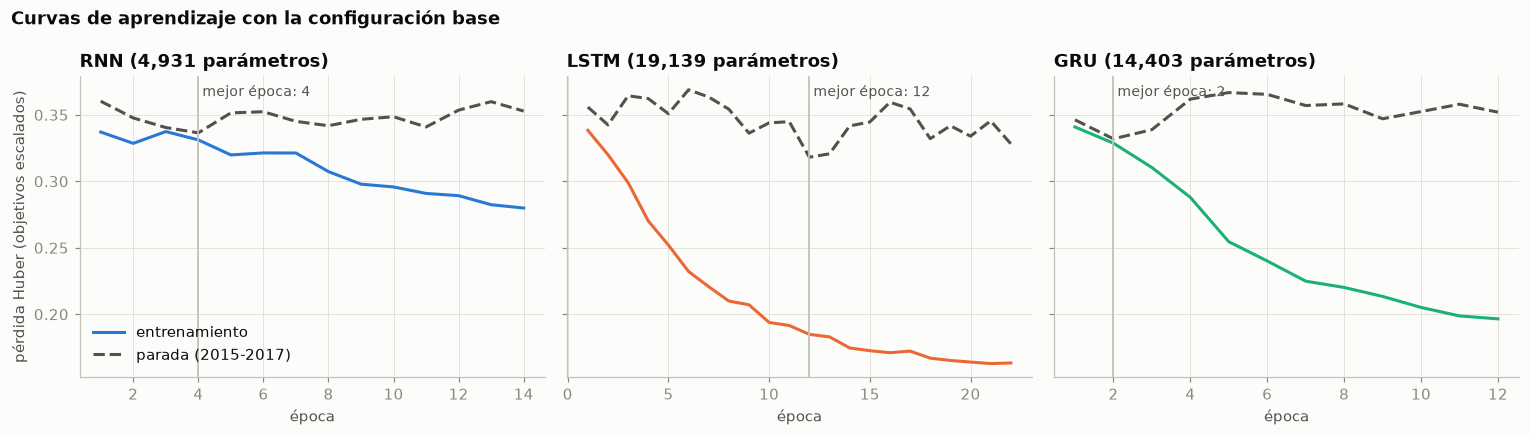

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (celda, r) in zip(axes, resultados.items()):
    h = r.historial
    ax.plot(h["época"], h["pérdida train"], color=COLOR_RED[celda], lw=2, label="entrenamiento")
    ax.plot(h["época"], h["pérdida parada"], color=TINTA_2, lw=2, ls="--", label="parada (2015-2017)")
    ax.axvline(r.mejor_epoca, color=EJE, lw=1.2)
    ax.text(r.mejor_epoca, 0.97, f" mejor época: {r.mejor_epoca}", transform=ax.get_xaxis_transform(),
            fontsize=9, color=TINTA_2, va="top")
    ax.set_title(f"{celda} ({r.parametros:,} parámetros)")
    ax.set_xlabel("época")
axes[0].set_ylabel("pérdida Huber (objetivos escalados)")
axes[0].legend(loc="lower left")
fig.suptitle("Curvas de aprendizaje con la configuración base", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

> **Cómo leer las curvas**
> - En las tres redes, la pérdida de **entrenamiento baja** de forma continua: aprenden… los datos con los que se entrenan.
> - La pérdida de **parada no baja**: oscila entre 0,32 y 0,37 desde la primera época. Lo que aprenden no sirve fuera del periodo de entrenamiento.
> - Es el patrón de **memorización** (sobreajuste): la distancia entre las dos curvas crece con las épocas, sobre todo en la LSTM (el entrenamiento pasa de 0,34 a 0,16) y en la GRU.
> - La parada temprana cumple su función y guarda la versión de la época 4 (RNN), 12 (LSTM) y 2 (GRU). En la RNN y la GRU, la mejor versión es casi la red recién empezada.
> - El zigzag de la curva de parada es normal: el trozo de parada es corto (unos 570 días) y la señal, débil.
>
> **Qué implica:** con la configuración base, las redes tienen demasiada capacidad para la poca señal que hay. La fase B tendrá que probar redes más pequeñas, más dropout, regularización L2 y velocidades de aprendizaje menores.

### 1.2 Resultados en validación (2018)

**MAE / ingenuo**: error del modelo dividido por el del ingenuo. Por debajo de 1, el modelo mejora al ingenuo.

In [5]:
errores_ingenuo = ev.errores(val)
filas, detalle = {}, {}
for nombre, prediccion in predicciones.items():
    comparacion = ev.comparar_con_ingenuo(ev.errores(val, prediccion), errores_ingenuo)
    detalle[nombre] = comparacion
    r = resultados.get(nombre)
    filas[nombre] = {**{f"MAE/ingenuo {h}": v for h, v in comparacion["MAE / ingenuo"].items()},
                     "puntuación (media)": ev.puntuacion(comparacion),
                     "parámetros": r.parametros if r else lineal.n_parametros,
                     "segundos": r.segundos if r else np.nan}
tabla = pd.DataFrame(filas).T
tabla

,MAE/ingenuo corto,MAE/ingenuo medio,MAE/ingenuo largo,puntuación (media),parámetros,segundos
RNN,0.992,1.035,1.171,1.066,"4,931.000",22.106
LSTM,1.075,1.262,4.082,2.140,"19,139.000",30.673
GRU,0.989,0.988,1.599,1.192,"14,403.000",35.230
Lineal,1.006,1.062,1.114,1.061,"1,443.000",NaN


In [6]:
# Error medio absoluto en $/barril (MAE) por horizonte
mae = pd.DataFrame({"Ingenuo": detalle["RNN"]["MAE ingenuo"],
                    **{nombre: d["MAE"] for nombre, d in detalle.items()}})
mae.T.round(2)

horizonte,corto,medio,largo
Ingenuo,2.450,9.040,9.050
RNN,2.440,9.360,10.590
LSTM,2.640,11.410,36.940
GRU,2.430,8.930,14.470
Lineal,2.470,9.600,10.080


### 1.3 Previsiones frente a la realidad (2018)

Cada punto del eje X es un día de 2018 en el que se hace la previsión. La línea oscura es el precio que **realmente** hubo *h* sesiones después; la gris, lo que dice el ingenuo (el precio de ese día); la de color, lo que previó cada red.

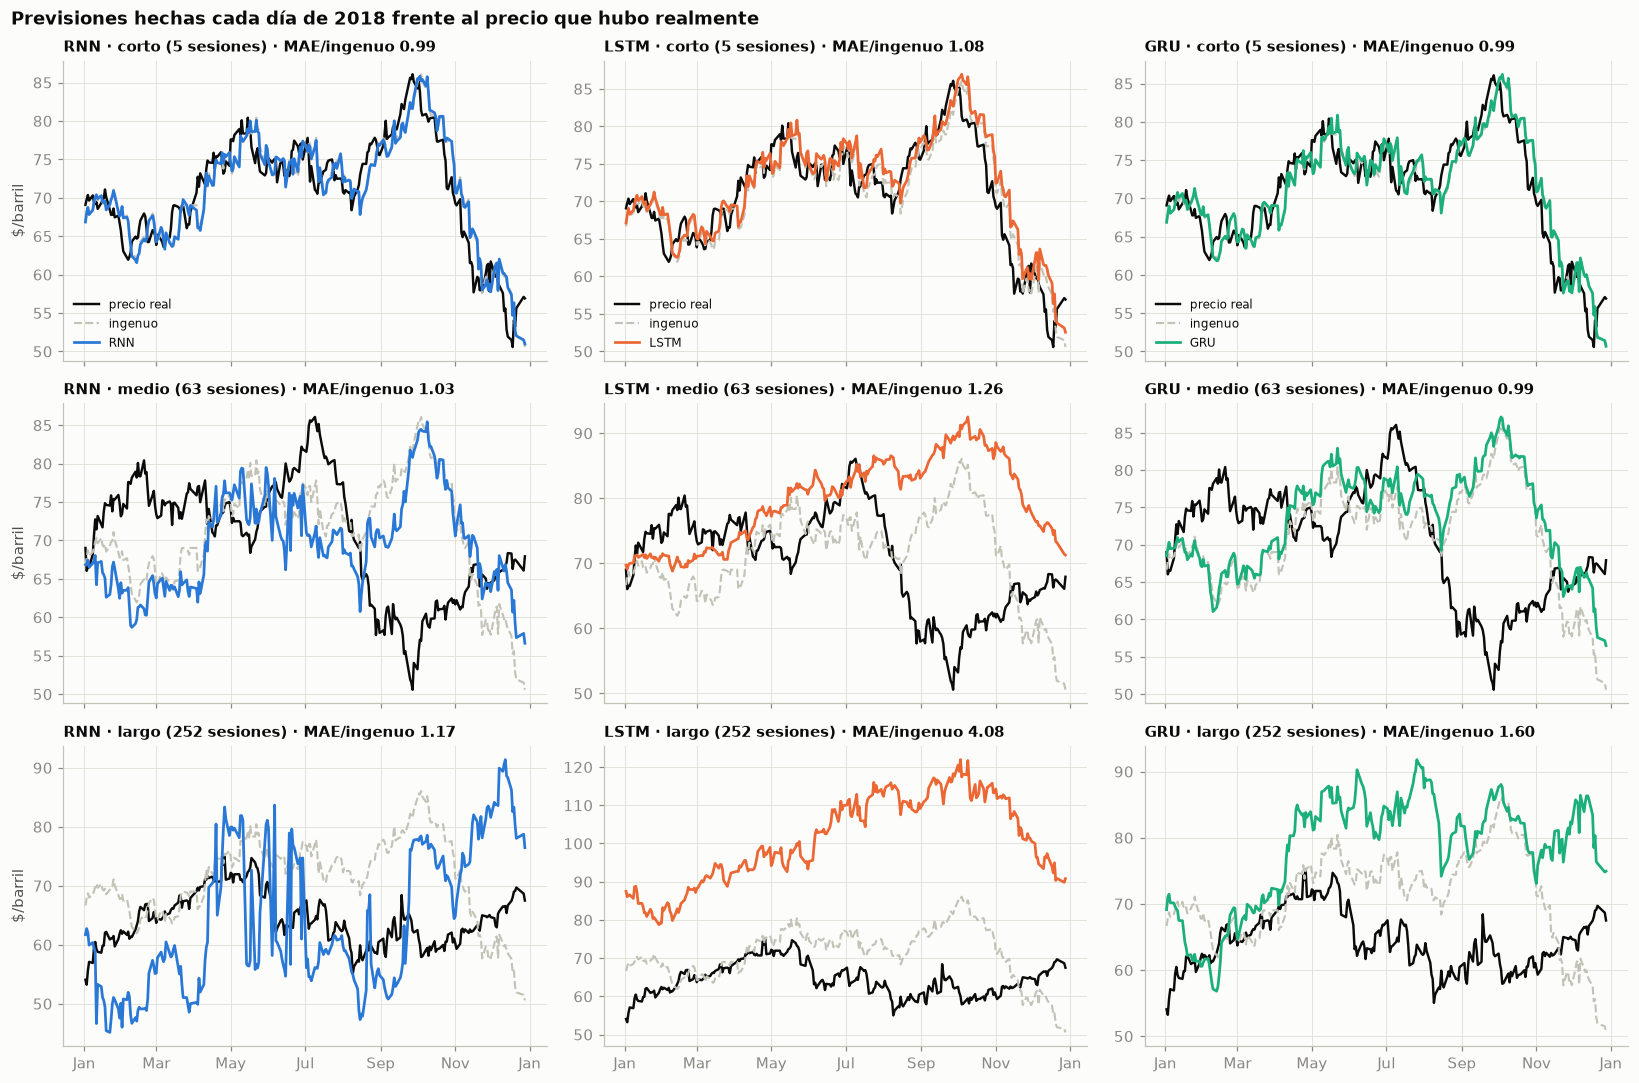

In [7]:
precio_futuro = {h: np.exp(val.Y[:, j]) * val.precio_origen for j, h in enumerate(val.horizontes)}
fig, axes = plt.subplots(3, 3, figsize=(15, 10), sharex=True)
for fila, (j, horizonte) in zip(axes, enumerate(val.horizontes)):
    for ax, celda in zip(fila, config.CELDAS):
        previsto = np.exp(predicciones[celda][:, j]) * val.precio_origen
        ax.plot(val.fechas, precio_futuro[horizonte], color=TINTA, lw=1.6, label="precio real")
        ax.plot(val.fechas, val.precio_origen, color=EJE, lw=1.4, ls="--", label="ingenuo")
        ax.plot(val.fechas, previsto, color=COLOR_RED[celda], lw=1.8, label=celda)
        ratio = detalle[celda].loc[horizonte, "MAE / ingenuo"]
        ax.set_title(f"{celda} · {horizonte} ({config.HORIZONTES[horizonte]} sesiones) · MAE/ingenuo {ratio:.2f}",
                     fontsize=10)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    fila[0].set_ylabel("$/barril")
for ax in axes[0]:
    ax.legend(loc="lower left", fontsize=8)
fig.suptitle("Previsiones hechas cada día de 2018 frente al precio que hubo realmente",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

> **Cómo leer las previsiones**
> - **A 5 sesiones (fila de arriba)**, las tres redes dibujan una línea casi pegada al precio real, pero también pegada al ingenuo: repiten el precio del día con pequeños retoques. Es el «espejismo» del que hablamos (D15): parece que aciertan, pero su error es prácticamente el mismo que el del ingenuo (MAE de 2,43 a 2,64 $ frente a 2,45 $).
> - **A 63 sesiones**, la GRU sigue de cerca al ingenuo y queda a la par (0,99). La LSTM se despega hacia arriba y prevé subidas que no llegan.
> - **A 252 sesiones está el problema:** las tres redes prevén precios **más altos** que el ingenuo durante casi todo 2018. La LSTM llega a prever entre 80 y 120 $ cuando el precio real un año después estuvo entre 55 y 75 $. Han aprendido la tendencia alcista del periodo de entrenamiento (el Brent pasó de unos 25 $ en 2002 a 140 $ en 2008) y la proyectan hacia el futuro. La RNN, además, salta de forma brusca de un día a otro.
> - El ingenuo también falla (en la segunda mitad de 2018 el precio cayó de 85 $ a 50 $), pero se equivoca menos porque no apuesta por nada.

### 1.4 Qué nos dice esta prueba

1. **El circuito funciona** de principio a fin (datos → fichas → entrenamiento → previsiones en $ → comparación con el ingenuo) y es **reproducible**: la misma semilla da los mismos números.
2. **Sin ajustar, ninguna red mejora claramente al ingenuo.** A corto plazo quedan a la par (0,99); a medio y largo plazo empeoran, sobre todo la LSTM. El modelo lineal queda cerca del ingenuo en los tres horizontes (1,01 / 1,06 / 1,11) y, a largo plazo, es más prudente que las redes.
3. **Dos problemas concretos para la fase B:** la **memorización** (curvas de aprendizaje) y el **sesgo alcista a largo plazo** (previsiones).
4. Es **un solo pliegue (2018) y una sola configuración**. Las conclusiones de verdad saldrán de las fases A y B, con los 4 pliegues.

Todo es coherente con lo que anticipaba el EDA (H1): la variación del Brent es casi impredecible a partir de su pasado. El reto real es conseguir que las redes **no empeoren** al ingenuo, sobre todo a largo plazo, y que aporten algo a corto plazo.

## 2. Fase A: estudio de ventana × recorte × indicador de nivel

**Objetivo (D6, D9, D16):** para cada horizonte, encontrar qué datos le sientan mejor a las redes:
- **ventana:** 10, 20, 40, 60, 120 o 252 días;
- **recorte de extremos:** ninguno, 0,5-99,5 % o 1-99 %;
- **indicador «caro o barato»:** con o sin.

Son 36 combinaciones por horizonte. Cada una se entrena con la **estructura base** en las tres redes y en todos los pliegues de validación (2018-2021; a 252 sesiones, 2018-2020). El modelo lineal se ajusta con 6 fuerzas de regularización y se toma la mejor.

**Medida:** «MAE / ingenuo», juntando las fichas de todos los pliegues. Por debajo de 1, el modelo mejora al ingenuo.

Los entrenamientos los hace `scripts/fase_a.py` y se guardan en `resultados/fase_a.csv`; aquí solo se leen y analizan. **Todo se mide con la estructura base y una sola semilla**, así que cada número lleva algo de ruido: las mejores combinaciones se confirman después con 3 semillas.

In [8]:
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import NullLocator

from oil_price import experimentos as ex
from oil_price.graficos import DIVERGENTE

# on_bad_lines="skip": por si el archivo se está escribiendo mientras se lee
resultados = pd.read_csv(config.DIR_RESULTADOS / "fase_a.csv", on_bad_lines="skip").dropna(subset=["MAE"])
redes_crudo = resultados[resultados["modelo"] != "Lineal"]

# Entrenamientos esperados por horizonte y ventana: 6 variantes × 3 redes × pliegues
esperados = {h: 6 * 3 * (3 if h == "largo" else 4) for h in config.HORIZONTES}
estado = (redes_crudo.pivot_table(index="horizonte", columns="ventana", values="MAE", aggfunc="size")
          .reindex(index=list(config.HORIZONTES), columns=config.VENTANAS).fillna(0).astype(int))
completas = [v for v in config.VENTANAS if all(estado.loc[h, v] == esperados[h] for h in config.HORIZONTES)]
print(f"Entrenamientos de redes: {len(redes_crudo):,} · del modelo lineal: {len(resultados) - len(redes_crudo):,}")
print(f"Ventanas completas: {completas}  ·  pendientes: {[v for v in config.VENTANAS if v not in completas]}")
estado

Entrenamientos de redes: 1,188 · del modelo lineal: 2,376
Ventanas completas: [10, 20, 40, 60, 120, 252]  ·  pendientes: []


ventana,10,20,40,60,120,252
horizonte,,,,,,
corto,72,72,72,72,72,72
medio,72,72,72,72,72,72
largo,54,54,54,54,54,54


In [9]:
resumen = ex.resumir(resultados)
resumen = resumen[resumen["ventana"].isin(completas)]
redes = resumen[resumen["modelo"] != "Lineal"]
lineal = resumen[resumen["modelo"] == "Lineal"]
CLAVE_DATOS = ["horizonte", "ventana", "recorte", "nivel"]
# Del modelo lineal se toma, en cada combinación, su mejor fuerza de regularización (su «ajuste»)
lineal_mejor = lineal.loc[lineal.groupby(CLAVE_DATOS)["MAE / ingenuo"].idxmin()]
NOMBRE_VARIANTE = {("ninguno", True): "sin recorte\ncon nivel", ("ninguno", False): "sin recorte\nsin nivel",
                   ("0.5-99.5", True): "0,5-99,5\ncon nivel", ("0.5-99.5", False): "0,5-99,5\nsin nivel",
                   ("1-99", True): "1-99\ncon nivel", ("1-99", False): "1-99\nsin nivel"}

### 2.1 Error según la ventana

Para cada horizonte, cómo cambia el error al mirar más o menos días atrás. Cada punto es la media de las 6 variantes de recorte y nivel. La línea gris horizontal es el ingenuo (= 1). **Cada panel tiene su propia escala**: los tres horizontes se mueven en rangos muy distintos.

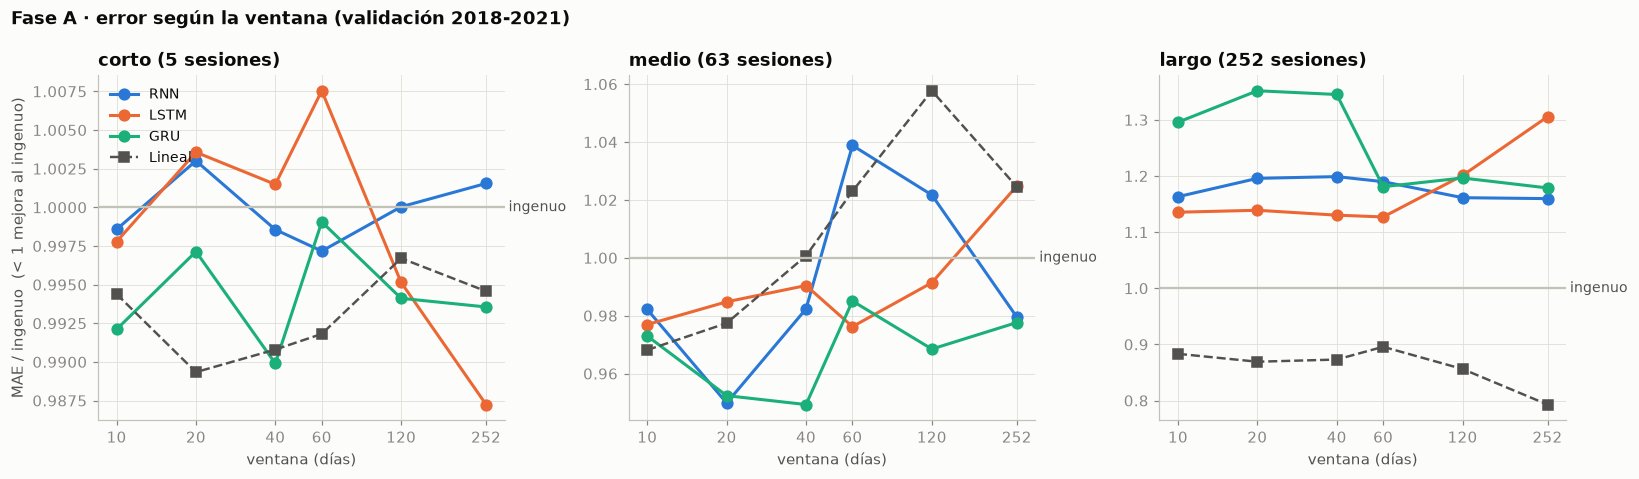

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, h in zip(axes, config.HORIZONTES):
    for celda, color in COLOR_RED.items():
        s = redes[(redes["horizonte"] == h) & (redes["modelo"] == celda)].groupby("ventana")["MAE / ingenuo"].mean()
        ax.plot(s.index, s.values, "o-", color=color, lw=2, ms=7, label=celda)
    s = lineal_mejor[lineal_mejor["horizonte"] == h].groupby("ventana")["MAE / ingenuo"].mean()
    ax.plot(s.index, s.values, "s--", color=TINTA_2, lw=1.6, ms=6, label="Lineal")
    ax.axhline(1, color=EJE, lw=1.5)
    ax.text(1.0, 1, " ingenuo", transform=ax.get_yaxis_transform(), va="center", fontsize=9, color=TINTA_2)
    ax.set_xscale("log")
    ax.set_xticks(completas, [str(v) for v in completas])
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlabel("ventana (días)")
    ax.set_title(f"{h} ({config.HORIZONTES[h]} sesiones)")
axes[0].set_ylabel("MAE / ingenuo  (< 1 mejora al ingenuo)")
axes[0].legend(loc="upper left", fontsize=9)
fig.suptitle("Fase A · error según la ventana (validación 2018-2021)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

### 2.2 Todas las combinaciones

Cada casilla es la media de las tres redes para una combinación. **Azul: mejora al ingenuo; rojo: empeora.** La intensidad del color se ajusta a cada horizonte, con una escala mínima de ±5 %: las diferencias menores que eso apenas se colorean, porque están dentro del ruido.

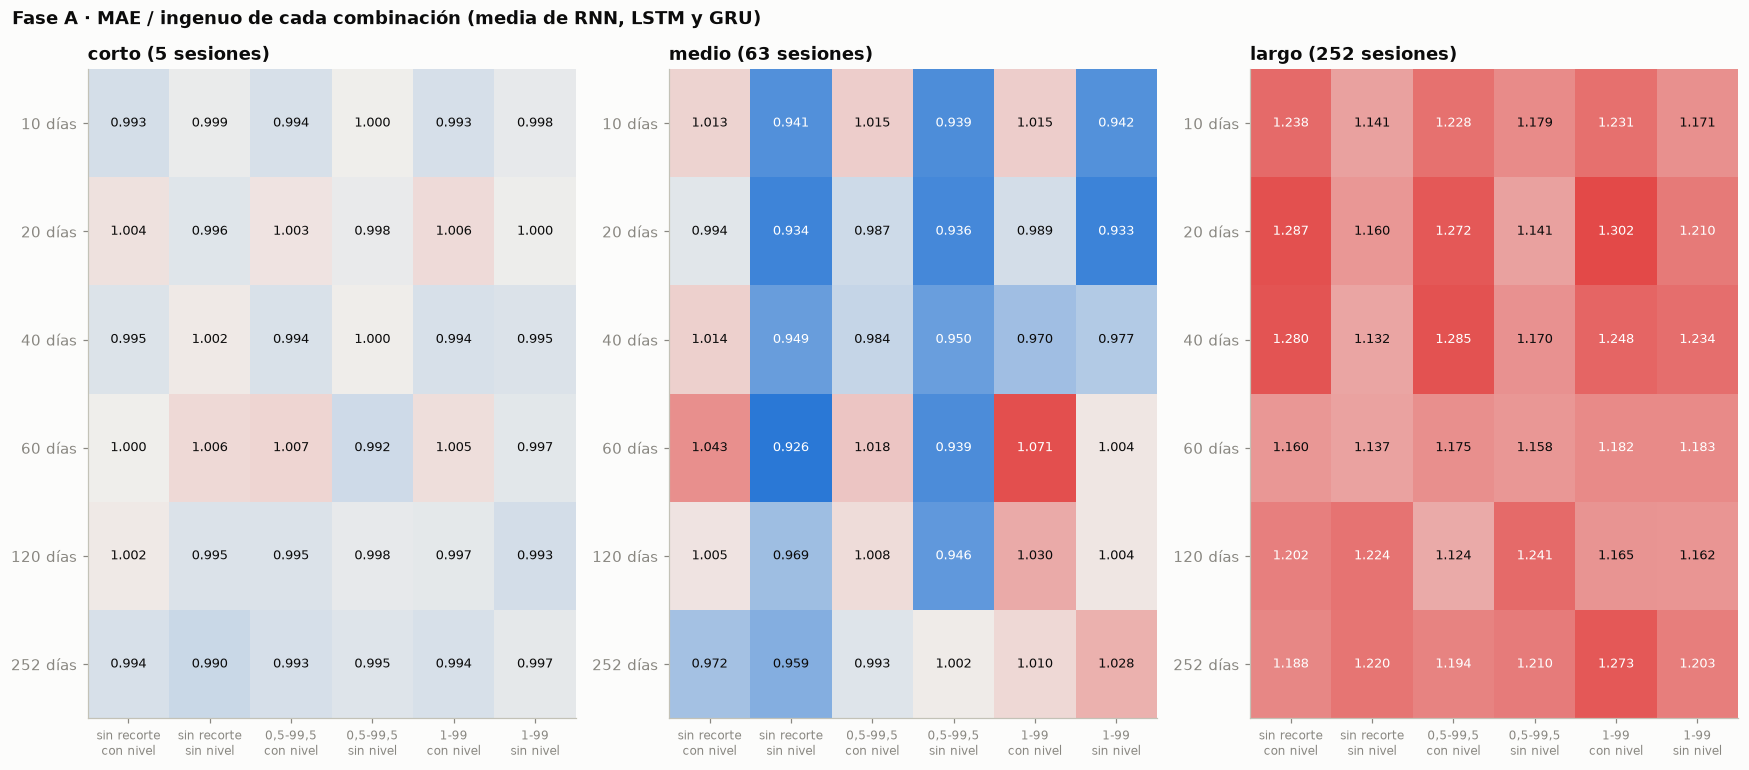

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 0.75 * len(completas) + 2.6))
for ax, h in zip(axes, config.HORIZONTES):
    tabla = (redes[redes["horizonte"] == h].groupby(["ventana", "recorte", "nivel"])["MAE / ingenuo"].mean()
             .unstack(["recorte", "nivel"]).reindex(columns=list(NOMBRE_VARIANTE)))
    distancia = max(abs(tabla.values - 1).max(), 0.05)   # escala mínima ±5 %: el ruido no se colorea
    norma = TwoSlopeNorm(vcenter=1, vmin=1 - distancia, vmax=1 + distancia)
    ax.imshow(tabla.values, cmap=DIVERGENTE.reversed(), norm=norma, aspect="auto")
    for i in range(tabla.shape[0]):
        for j in range(tabla.shape[1]):
            valor = tabla.values[i, j]
            ax.text(j, i, f"{valor:.3f}", ha="center", va="center", fontsize=8.5,
                    color="#ffffff" if abs(valor - 1) > 0.6 * distancia else TINTA)
    ax.set_xticks(range(tabla.shape[1]), [NOMBRE_VARIANTE[c] for c in tabla.columns], fontsize=8)
    ax.set_yticks(range(tabla.shape[0]), [f"{v} días" for v in tabla.index])
    ax.grid(False)
    ax.set_title(f"{h} ({config.HORIZONTES[h]} sesiones)")
fig.suptitle("Fase A · MAE / ingenuo de cada combinación (media de RNN, LSTM y GRU)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

### 2.3 Efecto medio del indicador de nivel y del recorte

In [12]:
efecto_nivel = redes.pivot_table(index="horizonte", columns="nivel", values="MAE / ingenuo", aggfunc="mean")
efecto_nivel.columns = ["sin nivel", "con nivel"]
efecto_recorte = redes.pivot_table(index="horizonte", columns="recorte", values="MAE / ingenuo", aggfunc="mean")
efecto_recorte = efecto_recorte[["ninguno", "0.5-99.5", "1-99"]].add_prefix("recorte ")
pd.concat([efecto_nivel, efecto_recorte], axis=1).reindex(list(config.HORIZONTES)).round(3)

,sin nivel,con nivel,recorte ninguno,recorte 0.5-99.5,recorte 1-99
horizonte,,,,,
corto,0.997,0.998,0.998,0.998,0.997
medio,0.960,1.007,0.977,0.976,0.998
largo,1.182,1.224,1.197,1.198,1.214


### 2.4 Clasificación

Las 5 mejores combinaciones de cada horizonte, ordenadas por la media de las tres redes (criterio D16). Al lado, el mejor modelo lineal con esos mismos datos.

In [13]:
por_red = redes.pivot_table(index=CLAVE_DATOS, columns="modelo", values="MAE / ingenuo")[config.CELDAS]
por_red["media redes"] = por_red.mean(axis=1)
por_red = por_red.join(lineal_mejor.set_index(CLAVE_DATOS)[["MAE / ingenuo", "alfa"]]
                       .rename(columns={"MAE / ingenuo": "Lineal", "alfa": "alfa lineal"}))
for h in config.HORIZONTES:
    print(f"{h} ({config.HORIZONTES[h]} sesiones)")
    display(por_red.loc[h].sort_values("media redes").head(5).round(3))

corto (5 sesiones)


,,,RNN,LSTM,GRU,media redes,Lineal,alfa lineal
ventana,recorte,nivel,,,,,,
252,ninguno,False,0.993,0.983,0.996,0.990,0.992,"100,000.000"
60,0.5-99.5,False,0.989,0.990,0.996,0.992,0.990,"100,000.000"
120,1-99,False,0.999,0.987,0.991,0.993,0.995,"100,000.000"
10,ninguno,True,0.999,0.990,0.990,0.993,0.996,"10,000.000"
252,0.5-99.5,True,0.997,0.987,0.996,0.993,0.998,"100,000.000"


medio (63 sesiones)


RNN  LSTM   GRU  media redes  Lineal  alfa lineal
ventana recorte  nivel                                                    
60      ninguno  False 0.962 0.902 0.913        0.926   1.007  100,000.000
20      1-99     False 0.939 0.942 0.919        0.933   0.965   10,000.000
        ninguno  False 0.949 0.942 0.910        0.934   0.966   10,000.000
        0.5-99.5 False 0.950 0.942 0.918        0.936   0.966   10,000.000
60      0.5-99.5 False 0.956 0.912 0.950        0.939   1.007  100,000.000

largo (252 sesiones)


,,,RNN,LSTM,GRU,media redes,Lineal,alfa lineal
ventana,recorte,nivel,,,,,,
120,0.5-99.5,True,1.074,1.126,1.170,1.124,0.874,"10,000.000"
40,ninguno,False,1.122,1.093,1.182,1.132,0.864,10.000
60,ninguno,False,1.129,1.101,1.181,1.137,0.870,1.000
10,ninguno,False,1.175,1.111,1.136,1.141,0.880,1.000
20,0.5-99.5,False,1.127,1.093,1.203,1.141,0.879,1.000


### 2.5 ¿Es estable año a año?

Para la mejor combinación de cada horizonte, el resultado de cada red **en cada año de validación**. Una combinación fiable debería mejorar al ingenuo en la mayoría de los años, no solo en uno.

In [14]:
mejores = {h: por_red.loc[h].sort_values("media redes").index[0] for h in config.HORIZONTES}
for h, (ventana, recorte, nivel) in mejores.items():
    filas = redes_crudo[(redes_crudo["horizonte"] == h) & (redes_crudo["ventana"] == ventana)
                        & (redes_crudo["recorte"] == recorte) & (redes_crudo["nivel"] == nivel)]
    tabla = filas.pivot_table(index="modelo", columns="pliegue", values="MAE / ingenuo").loc[config.CELDAS]
    tabla.loc["MAE ingenuo ($)"] = filas.groupby("pliegue")["MAE ingenuo"].first()
    print(f"{h}: ventana {ventana}, recorte {recorte}, {'con' if nivel else 'sin'} nivel")
    display(tabla.round(3))

corto: ventana 252, recorte ninguno, sin nivel


pliegue,2018,2019,2020,2021
modelo,,,,
RNN,1.001,0.997,0.984,0.991
LSTM,0.988,0.991,0.981,0.972
GRU,0.991,1.001,0.988,1.006
MAE ingenuo ($),2.455,1.920,2.873,2.297


medio: ventana 60, recorte ninguno, sin nivel


pliegue,2018,2019,2020,2021
modelo,,,,
RNN,0.921,0.978,0.939,1.082
LSTM,0.947,0.905,0.869,0.919
GRU,0.937,0.901,0.913,0.896
MAE ingenuo ($),9.040,8.523,15.787,6.597


largo: ventana 120, recorte 0.5-99.5, con nivel


pliegue,2018,2019,2020
modelo,,,
RNN,1.099,1.719,0.572
LSTM,0.847,2.017,0.524
GRU,1.515,1.983,0.444
MAE ingenuo ($),9.048,23.075,30.265


### 2.6 El modelo lineal

In [15]:
efecto_alfa = lineal.pivot_table(index="horizonte", columns="alfa", values="MAE / ingenuo", aggfunc="mean")
print("MAE / ingenuo del lineal según la fuerza de regularización (media de ventanas y variantes):")
display(efecto_alfa.reindex(list(config.HORIZONTES)).round(3))

comparacion = pd.DataFrame({
    "mejor red (media de las 3)": por_red.groupby(level="horizonte")["media redes"].min(),
    "mejor red individual": por_red[config.CELDAS].groupby(level="horizonte").min().min(axis=1),
    "mejor lineal": por_red.groupby(level="horizonte")["Lineal"].min(),
}).reindex(list(config.HORIZONTES))
print("Mejor resultado de cada tipo de modelo (MAE / ingenuo):")
comparacion.round(3)

MAE / ingenuo del lineal según la fuerza de regularización (media de ventanas y variantes):


alfa,1.000,10.000,100.000,"1,000.000","10,000.000","100,000.000"
horizonte,,,,,,
corto,1.149,1.116,1.087,1.041,1.000,0.994
medio,1.094,1.083,1.064,1.048,1.038,1.014
largo,0.920,0.902,0.881,0.880,0.898,0.932


Mejor resultado de cada tipo de modelo (MAE / ingenuo):


,mejor red (media de las 3),mejor red individual,mejor lineal
horizonte,,,
corto,0.990,0.983,0.988
medio,0.926,0.901,0.951
largo,1.124,1.074,0.759


Como el lineal gana con claridad a 1 año, conviene mirar si lo hace **todos los años o solo en uno**. Para cada horizonte, su mejor versión (combinación y fuerza de regularización elegidas con todos los pliegues), año a año:

In [16]:
filas = []
for h in config.HORIZONTES:
    mejor = lineal[lineal["horizonte"] == h].sort_values("MAE / ingenuo").iloc[0]
    sel = resultados[(resultados["modelo"] == "Lineal") & (resultados["horizonte"] == h)
                     & (resultados["ventana"] == mejor["ventana"]) & (resultados["recorte"] == mejor["recorte"])
                     & (resultados["nivel"] == mejor["nivel"]) & (resultados["alfa"] == mejor["alfa"])]
    filas.append(sel.set_index("pliegue")["MAE / ingenuo"].rename(
        f"{h}: ventana {mejor['ventana']}, recorte {mejor['recorte']}, "
        f"{'con' if mejor['nivel'] else 'sin'} nivel, alfa {mejor['alfa']:g}"))
print("Mejor modelo lineal de cada horizonte, año a año (MAE / ingenuo):")
pd.DataFrame(filas).round(3)

Mejor modelo lineal de cada horizonte, año a año (MAE / ingenuo):


pliegue,2018,2019,2020,2021
"corto: ventana 20, recorte 0.5-99.5, sin nivel, alfa 10000",0.995,0.991,0.982,0.987
"medio: ventana 10, recorte ninguno, sin nivel, alfa 1000",0.992,0.919,0.925,1.019
"largo: ventana 252, recorte ninguno, sin nivel, alfa 1000",0.810,1.020,0.543,NaN


### 2.7 Lectura de la fase A

> Las 6 ventanas completas: 1.188 entrenamientos de redes y 2.376 del modelo lineal. Estructura base y una sola semilla: cada número lleva algo de ruido, y las mejores combinaciones se confirman con 3 semillas antes de elegir.

**1 semana (5 sesiones): ninguna combinación aporta nada apreciable.**
- Todo queda entre 0,98 y 1,01, tanto en las redes como en el lineal. La mejor de media es la ventana de 252 días sin recorte ni nivel (0,990).
- Ni la ventana, ni el recorte, ni el indicador cambian nada de forma clara: las diferencias rondan el 0,5 %, dentro del ruido.

**3 meses (63 sesiones): la mejora más clara del estudio.**
- Con las mejores combinaciones, las redes mejoran al ingenuo un **6-7 %** de media (0,93), y la LSTM y la GRU llegan al 9-10 % (0,90-0,91).
- Hay **dos candidatas**, ambas sin indicador de nivel:
  - **60 días sin recorte** (0,926): la mejor, y la LSTM y la GRU mejoran al ingenuo los cuatro años. Pero es **frágil**: con recorte 1-99 pasa a 1,004.
  - **20 días** (0,933-0,936): da prácticamente lo mismo con los tres recortes, aunque en 2018 apenas mejora al ingenuo.
  - Las separa menos de un 1 %: es un empate dentro del ruido, y la confirmación con semillas decidirá.
- Las ventanas largas (120 y 252 días) no mejoran a las cortas: para prever a 3 meses no hace falta mirar más de 2-3 meses atrás.
- El factor decisivo sigue siendo **quitar el indicador de nivel** (0,96 sin él frente a 1,01 con él).
- Aquí **las redes superan al lineal** (0,93 frente a 0,95), y el lineal empeora con las ventanas largas.

**1 año (252 sesiones): las redes empeoran al ingenuo con cualquier combinación; el lineal lo mejora con claridad.**
- Las 36 combinaciones de las redes quedan entre 1,12 y 1,30: ninguna ventana corrige el problema. Además, aciertan si el precio sube o baja solo el 46 % de las veces, menos que una moneda al aire.
- El lineal mejora al ingenuo con todas las ventanas (0,79-0,90 de media), sobre todo con las largas: con 252 días llega a **0,76**.
- **Qué hace el lineal: apuesta por la corrección.** Tras una subida fuerte prevé una bajada; tras una caída, un rebote. Con 252 días de historia «ve» el último año completo. Le sale muy bien en 2020 (tras el desplome prevé un rebote fuerte, y lo hubo: 0,54), regular en 2018 (prevé una bajada y la hubo: 0,81) y nada en 2019 (1,02: la caída por la COVID era imprevisible).
- **Con cautela:** solo hay 3 años independientes, casi toda la ventaja viene de 2020, y el 0,76 es el mejor de 216 intentos (36 combinaciones × 6 fuerzas de regularización), así que es algo optimista. El test dirá si se sostiene.

**Otras observaciones**
- **El indicador de nivel empeora a las redes** a 3 meses y a 1 año, al contrario de lo que esperaba la hipótesis H6. El lineal sí aprovecha la idea de corrección, pero sobre todo a través de la ventana de 252 días, que contiene la misma información (cuánto ha subido o bajado el precio en el último año).
- **El recorte apenas influye** en ningún horizonte (diferencias de hasta un 2 %).
- **Las redes base memorizan con todas las ventanas:** su mejor época media está entre la 4 y la 6. La fase B, con redes más pequeñas y más reguladas, es la ocasión de corregirlo, sobre todo a 1 año.
- **Coste:** la ventana de 252 días multiplica el tiempo (GRU: unos 78 s por entrenamiento, frente a 5 s con 10 días) y no mejora a las redes.
- La hipótesis H1 («solo se mejora a 1 semana») **no se cumple en validación**: el horizonte que se mejora es el de 3 meses (y a 1 año, solo el lineal).